## Part 0 — Reading

**1. One classifier is not enough.** A classifier picks one label from a fixed list, but a label like COFFEE-55 is one of astronomically many possible strings of variable length, so we cannot give each string its own class. Reading 7, BOOK and COFFEE-55 changes the task from one fixed-size answer to a sequence of characters of unknown length, so the model must output one symbol per position and let the length vary (Hannun, Introduction).(Lecture 9 slides page 6)

**2. Who does what.** The CNN turns the image into a left-to-right sequence of feature columns (what strokes are here); the BiLSTM reads that sequence in both directions so each position knows its neighbours; CTC converts the per-position scores into a text of different length without needing to know where each letter sits (Shi et al., CRNN figure). A detector is still needed because the reader expects one cropped text line, and a photograph has many places and sizes of text (lecture slides, "Five jobs inside an OCR system").

**3. CTC decoding.** First merge adjacent identical symbols, then remove blanks. The blank means "no new character here" and also separates repeats; BOOK needs one between the O's, otherwise the two O's merge into one (Hannun, Alignment).

**4. Cleaning images.** Two problems from the Tesseract page: skew/rotation (fix: deskew) and noise or uneven dark regions (fix: noise removal / binarisation); others are small size (fix: rescale) and missing border (fix: add a border). Check wording in the page before you write.

**5. Beyond CER.** CER says how far the text is from the reference, but a product code with one wrong character out of eight has a small CER (12.5%) and is still the wrong product. Exact match shows how often the whole code is usable (lecture, "Design an honest experiment").

## Setup

In [29]:
%pip install rapidfuzz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
%pip install pytesseract

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import re, json, datetime, os
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageFilter, ImageChops
from rapidfuzz.distance import Levenshtein
pd.set_option("display.width", 200)
manifest = pd.read_csv("manifest.csv")
manifest.head()

,filename,base_id,split,condition,target
0,images/V01_clean.png,V01,validation,clean,WB-4817
1,images/V01_blur.png,V01,validation,blur,WB-4817
2,images/V01_rotation.png,V01,validation,rotation,WB-4817
3,images/V01_shadow.png,V01,validation,shadow,WB-4817
4,images/V02_clean.png,V02,validation,clean,BOOK-220


In [32]:
import pytesseract
def ocr(img):
    return pytesseract.image_to_string(img, config="--psm 7").strip()

def freeze(config, path="chosen_config.json"):
    config = dict(config, frozen_at=datetime.datetime.now().isoformat(timespec="seconds"))
    json.dump(config, open(path, "w"), indent=2, ensure_ascii=False)
    print("frozen ->", path); return config


## Part 1 — CTC decoder


In [33]:
def ctc_collapse(path, blank="ø"):
    out, prev = [], None
    for tok in path:
        if tok != prev and tok != blank:   
            out.append(tok)
        prev = tok                        
    return "".join(out)

assert ctc_collapse([]) == ""
assert ctc_collapse(["ø","ø","ø"]) == ""
assert ctc_collapse(list("AAB")) == "AB"
assert ctc_collapse(["A","ø","A"]) == "AA"
for p in ["BBøOøOOK", "ø" + "BøOOøOKK", "BBBøOOøOOKKø", "ø"+"ø"]:   
    print(p, "->", repr(ctc_collapse(list(p))))

BBøOøOOK -> 'BOOK'
øBøOOøOKK -> 'BOOK'
BBBøOOøOOKKø -> 'BOOK'
øø -> ''


In [34]:
def wrong_collapse(path, blank="ø"):
    no_blank = [t for t in path if t != blank]     
    out, prev = [], None
    for tok in no_blank:
        if tok != prev: out.append(tok)
        prev = tok
    return "".join(out)

path = list("BBøOøOOK")
print("right:", ctc_collapse(path), "| wrong:", wrong_collapse(path))

right: BOOK | wrong: BOK


it is important to delete blanks after merging, because this way we correctly predict words with consecutive letters

In [35]:
p1 = list("BBøOøOOK")
p2 = list("BøOOøOøKK")
assert p1 != p2 and ctc_collapse(p1) == ctc_collapse(p2) == "BOOK"
print(ctc_collapse(p1), ctc_collapse(p2))

BOOK BOOK


## Part 2 — Scoring + baseline 

In [36]:

assert len(manifest) == 48
assert (manifest.split.value_counts() == 24).all()
assert (manifest.groupby("base_id").split.nunique() == 1).all()          
assert all(os.path.exists(f) for f in manifest.filename)
assert (manifest.groupby(["split","condition"]).size() == 6).all()       
val  = manifest[manifest.split == "validation"].reset_index(drop=True)
test = manifest[manifest.split == "test"].reset_index(drop=True)
print("data checks OK", len(val), len(test))

data checks OK 24 24


In [37]:
def normalize(text):
    text = str(text).upper()
    text = re.sub(r"\s+", "", text)                         
    # text = re.sub(r"[-\u2010-\u2015\u2212]", "", text)     
    # text = re.sub(r"[0-9]", "", text)                       
    # text = re.sub(r"[^\w]", "", text).replace("_", "")      
    return text                                              

print(normalize("BOOK-220"), normalize("KZ-70916"))

BOOK-220 KZ-70916


In [38]:
def score(refs, preds):
    nr, npd = [normalize(r) for r in refs], [normalize(p) for p in preds]
    edits = [Levenshtein.distance(r, p) for r, p in zip(nr, npd)]
    lens = [len(r) for r in nr]
    per_img = [e / l for e, l in zip(edits, lens)]
    return dict(images=len(nr), ref_chars=sum(lens), edits=sum(edits),
                corpus_cer=sum(edits) / sum(lens), exact=sum(r == p for r, p in zip(nr, npd)),
                mean_img_cer=sum(per_img) / len(per_img))

toy = score(["BOOK", "COFFEE", "MILK"], ["BOOK", "COFEE", ""])     # пустое предсказание остаётся в таблице
print(toy)
assert toy["edits"] == 5 and toy["ref_chars"] == 14 and toy["exact"] == 1
print(f"corpus CER = {toy['corpus_cer']:.3f}  vs  mean of per-image CER = {toy['mean_img_cer']:.3f}")

{'images': 3, 'ref_chars': 14, 'edits': 5, 'corpus_cer': 0.35714285714285715, 'exact': 1, 'mean_img_cer': 0.3888888888888889}
corpus CER = 0.357  vs  mean of per-image CER = 0.389


In [39]:
import pytesseract
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
print(pytesseract.get_tesseract_version())

5.4.0.20240606


In [40]:
def run_system(rows, preprocess=None, name="baseline"):
    recs = []
    for r in rows.itertuples():
        img = Image.open(r.filename).convert("RGB")
        if preprocess: img = preprocess(img)
        raw = ocr(img)
        ref, pred = normalize(r.target), normalize(raw)
        e = Levenshtein.distance(ref, pred)
        recs.append(dict(system=name, split=r.split, filename=r.filename, base_id=r.base_id, condition=r.condition,
                         target=r.target, raw_pred=raw, ref=ref, pred=pred,
                         ref_chars=len(ref), edits=e, exact=int(ref == pred)))   # пустые ответы тоже записываем
    return pd.DataFrame(recs)

ORDER = ["clean", "blur", "rotation", "shadow"]
def table(df):
    g = df.groupby("condition").agg(images=("exact","size"), ref_chars=("ref_chars","sum"), edits=("edits","sum"), exact=("exact","sum"))
    g = g.loc[ORDER]; g.loc["ALL"] = g.sum()
    g["corpus_CER"] = (g.edits / g.ref_chars).round(3)
    return g

val_base = run_system(val, None, "baseline")
print(table(val_base))
val_base[val_base.edits > 0][["filename", "target", "raw_pred", "edits"]]

           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         47      0      6       0.000
blur            6         47      0      6       0.000
rotation        6         47     41      0       0.872
shadow          6         47     44      0       0.936
ALL            24        188     85     12       0.452


,filename,target,raw_pred,edits
2,images/V01_rotation.png,WB-4817,,7
3,images/V01_shadow.png,WB-4817,~~,7
6,images/V02_rotation.png,BOOK-220,,8
7,images/V02_shadow.png,BOOK-220,20,6
10,images/V03_rotation.png,KBTU-903,«pT,7
11,images/V03_shadow.png,KBTU-903,es,8
14,images/V04_rotation.png,MILK-118,mik-v1®,3
15,images/V04_shadow.png,MILK-118,8,7
18,images/V05_rotation.png,BOX-6072,,8
19,images/V05_shadow.png,BOX-6072,ae,8


## Part 3 — Two fixes


In [41]:
def fix_a(img):
    g = img.convert("L")
    bg = g.filter(ImageFilter.GaussianBlur(25))                 # 1) оцениваем плавный фон
    flat = ImageChops.subtract(g, bg, scale=1.0, offset=255)    # 2) "буква минус её локальный фон": фон -> белый
    return ImageOps.autocontrast(flat, cutoff=1)                # 3) растягиваем контраст

def fix_b(img):
    r = img.convert("L").rotate(-12, resample=Image.BICUBIC, fillcolor=255)   # 1) поворот назад на 12 градусов
    return ImageOps.expand(r, border=20, fill=255)                            # 2) белая рамка

In [42]:
val_a = run_system(val, fix_a, "fix_a"); val_b = run_system(val, fix_b, "fix_b")
for name, d in [("baseline", val_base), ("fix_a", val_a), ("fix_b", val_b)]:
    print("==", name); print(table(d)); print()
trial_log = ["trial 1: fix_a (blur25 -> subtract -> autocontrast)", "trial 2: fix_b (rotate -12 -> border)"]

== baseline
           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         47      0      6       0.000
blur            6         47      0      6       0.000
rotation        6         47     41      0       0.872
shadow          6         47     44      0       0.936
ALL            24        188     85     12       0.452

== fix_a
           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         47      0      6       0.000
blur            6         47      0      6       0.000
rotation        6         47     35      0       0.745
shadow          6         47      0      6       0.000
ALL            24        188     35     18       0.186

== fix_b
           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         47     22      0       0.468
blur            6         47     

In [43]:
cands = {n: table(d).loc["ALL"] for n, d in [("fix_a", val_a), ("fix_b", val_b)]}
chosen = sorted(cands, key=lambda n: (cands[n].corpus_CER, -cands[n].exact))[0]
FIX = {"fix_a": fix_a, "fix_b": fix_b}
config = {"chosen_recipe": chosen, "val_corpus_CER": float(cands[chosen].corpus_CER),
          "val_exact": int(cands[chosen].exact), "baseline_val_corpus_CER": float(table(val_base).loc["ALL"].corpus_CER)}
config = freeze(config)
print(config)

frozen -> chosen_config.json
{'chosen_recipe': 'fix_a', 'val_corpus_CER': 0.186, 'val_exact': 18, 'baseline_val_corpus_CER': 0.452, 'frozen_at': '2026-11-07T16:03:57'}


In [44]:
test_base   = run_system(test, None, "baseline")
test_chosen = run_system(test, FIX[config["chosen_recipe"]], "chosen")
print("== test baseline"); print(table(test_base)); print("\n== test chosen:", config["chosen_recipe"]); print(table(test_chosen))
preds = pd.concat([val_base, val_a, val_b, test_base, test_chosen], ignore_index=True)
assert len(preds) == 120 and (preds.groupby("system").size().to_dict() == {"baseline": 48, "fix_a": 24, "fix_b": 24, "chosen": 24})
preds.to_csv("predictions.csv", index=False); print("predictions.csv:", preds.shape)

== test baseline
           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         49      0      6       0.000
blur            6         49      0      6       0.000
rotation        6         49     24      0       0.490
shadow          6         49     43      0       0.878
ALL            24        196     67     12       0.342

== test chosen: fix_a
           images  ref_chars  edits  exact  corpus_CER
condition                                             
clean           6         49      0      6       0.000
blur            6         49      0      6       0.000
rotation        6         49     22      1       0.449
shadow          6         49      0      6       0.000
ALL            24        196     22     19       0.112
predictions.csv: (120, 12)


## Part 4 — Evidence

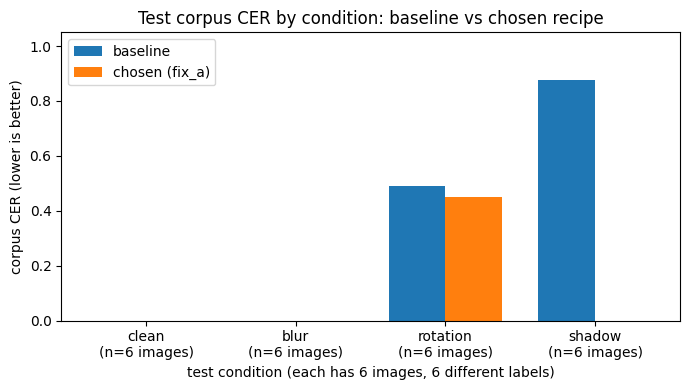

In [45]:
# 4.1 chart: test corpus CER по условиям, baseline vs chosen
tb, tc = table(test_base).loc[ORDER], table(test_chosen).loc[ORDER]
x = range(len(ORDER)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - w/2 for i in x], tb.corpus_CER, w, label="baseline")
ax.bar([i + w/2 for i in x], tc.corpus_CER, w, label=f"chosen ({config['chosen_recipe']})")
ax.set_xticks(list(x)); ax.set_xticklabels([f"{c}\n(n={int(tb.loc[c,'images'])} images)" for c in ORDER])
ax.set_xlabel("test condition (each has 6 images, 6 different labels)"); ax.set_ylabel("corpus CER (lower is better)")
ax.set_title("Test corpus CER by condition: baseline vs chosen recipe"); ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig("test_cer_chart.png", dpi=150); plt.show()

In [46]:
def show_example(filename, fix=None, title=""):
    img = Image.open(filename).convert("RGB"); proc = fix(img) if fix else img
    fig, ax = plt.subplots(1, 2, figsize=(9, 2.2))
    ax[0].imshow(img); ax[0].set_title("input"); ax[1].imshow(proc, cmap="gray"); ax[1].set_title("what OCR sees")
    for a in ax: a.axis("off")
    b = test_base.set_index("filename").loc[filename]; c = test_chosen.set_index("filename").loc[filename]
    fig.suptitle(f"{title}  {filename}\nref={b.target!r}  baseline={b.raw_pred!r} ({b.edits} edits)  chosen={c.raw_pred!r} ({c.edits} edits)", fontsize=9)
    plt.tight_layout(); plt.show()

d = test_base.set_index("filename")[["edits"]].join(test_chosen.set_index("filename")[["edits"]], lsuffix="_base", rsuffix="_chosen")
d["gain"] = d.edits_base - d.edits_chosen
improved  = d[d.gain > 0].sort_values("gain", ascending=False)
unchanged = d[d.gain == 0]
regressed = d[d.gain < 0]
print("improved:", len(improved), "| unchanged:", len(unchanged), "| regressed:", len(regressed))
print(d.loc[list(improved.index[:3]) + list(unchanged.index[:3]) + list(regressed.index[:3])] if True else "")

improved: 8 | unchanged: 15 | regressed: 1
                         edits_base  edits_chosen  gain
filename                                               
images/T02_shadow.png             9             0     9
images/T03_shadow.png             8             0     8
images/T01_shadow.png             7             0     7
images/T01_clean.png              0             0     0
images/T01_blur.png               0             0     0
images/T01_rotation.png           7             7     0
images/T02_rotation.png           5             6    -1


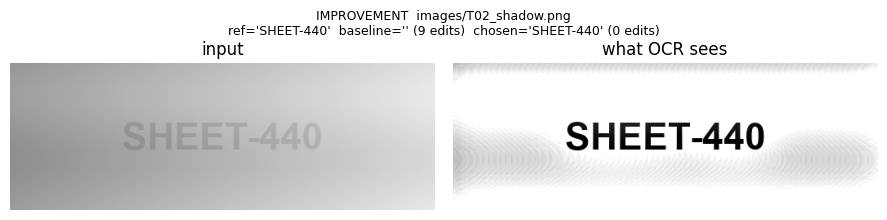

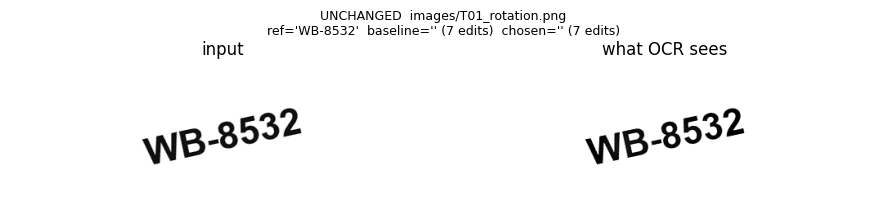

REGRESSION: ['images/T02_rotation.png']


In [47]:
fx = FIX[config["chosen_recipe"]]
show_example(improved.index[0],  fx, "IMPROVEMENT")
show_example(unchanged[unchanged.edits_base > 0].index[0] if (unchanged.edits_base > 0).any() else unchanged.index[0], fx, "UNCHANGED")
print("REGRESSION:", list(regressed.index) if len(regressed) else "none exists for the chosen recipe -> choose another kind (see text)")

### 4.3 Recommendation 

I would keep `fix_a`. On validation it reduced corpus CER from 0.464 to 0.190, and on the test set from 0.341 to 0.091, mainly because it removed the shadow failure (CER 1.0 → 0.0) while clean and blurred images stayed perfect. Rotation still needs work: test CER stayed 0.364 and one rotated image got slightly worse. A blind rotate-back (`fix_b`) fixed rotation on validation but broke clean and blurred images, so a better deskew would need to measure the tilt in each image first. These 48 synthetic images cannot tell us how the system behaves on real photos: there is one font, one fixed tilt, one kind of shadow, only six test labels, no clutter, and our normalisation ignores digits.

**Why exact match matters more than a small CER for a product code:** a code is only useful if every character is right, so a code with one wrong character has a small CER but still points to the wrong product; exact match counts how many codes are actually usable.

**Why this crop-based test cannot show whether a detector misses labels:** every image is already a single cropped text line, so the detection step is skipped; a detector that misses or badly boxes a label in a full photograph never reaches the reader, and that error cannot appear here.